In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd

/home/floriann/.conda/envs/uf-ml/lib/python3.8/site-packages/geopandas/_compat.py:124: UserWarning: The Shapely GEOS version (3.11.4-CAPI-1.17.4) is incompatible with the GEOS version PyGEOS was compiled with (3.10.1-CAPI-1.16.0). Conversions between both will be slow.
  warnings.warn(
/p/tmp/floriann/anaconda/ipykernel_961386/737201067.py:5: DeprecationWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas still uses PyGEOS by default. However, starting with version 0.14, the default will switch to Shapely. To force to use Shapely 2.0 now, you can either uninstall PyGEOS or set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In the next release, GeoPandas will switch to using Shapely by default, even if PyGEOS is installed. If you only have PyGEOS installed to get speed-ups, this switch should be smooth. However,

# Determine prediction approach depending on regional attribute coverage

**Base premise**: Local models usually outperform EU-wide models when sufficient local training data is available. 

**Our modeling approach**: Infer missing attributes using models with the smallest geographic training scope that still provides at least 100k training samples.

### Determine attribute coverage at country-level

In [ ]:
import pyarrow.parquet as pq

def attr_coverage_country(path_pattern: str, columns: list):
    files = glob.glob(str(path_pattern))
    
    total_rows = 0
    floors_height_sum = 0
    nna_sums = pd.Series(0, index=columns, dtype="int64")
    
    for f in files:
        try:
            cols_avail = pq.ParquetFile(f).schema.names
            cols = list(set(columns).intersection(set(cols_avail)))
            df = pd.read_parquet(f, columns=cols + ['height_source'])

            floors_height_sum += ((df['height_source'] == 'floors') & (df['floors'].notna())).sum()
            nna_sums += df[cols].notna().sum()
            total_rows += len(df)
        except Exception as e:
            print(f"Error processing file {f}")
            raise e

    nna_sums['height_floor_derived'] = floors_height_sum
    nna_sums['height'] -= floors_height_sum

    return nna_sums / total_rows

attr_coverage = pd.DataFrame()
data_path = Path('/p/projects/eubucco/data/4-merged-dataset-ml-cleaned')
countries = pd.read_csv('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts_extra.csv')['CNTR_CODE'].unique().tolist()
for country in countries:
    attr_coverage[country] = attr_coverage_country(data_path / f'{country}*.parquet', ['height', 'type', 'residential_type', 'age', 'floors', 'osm_height_merged', 'osm_type_merged', 'osm_residential_type_merged', 'osm_age_merged', 'msft_height_merged'])

attr_coverage.T.sort_values(by='height', ascending=False).to_csv('/p/projects/eubucco/data/overview-metrics/country-attribute-coverage-4-merged-dataset-ml-cleaned.csv')
attr_coverage.T.round(3).sort_values(by='residential_type', ascending=False)

,height,type,residential_type,age,floors,osm_height_merged,osm_type_merged,osm_residential_type_merged,osm_age_merged,height_floor_derived
IE,0.048,0.553,0.380,0.000,0.080,NaN,NaN,NaN,NaN,0.079
NO,0.006,0.780,0.374,0.001,0.041,NaN,NaN,NaN,NaN,0.039
SK,0.833,0.769,0.317,0.000,0.001,0.026,0.077,0.049,0.000,0.001
UK,0.331,0.360,0.240,0.001,0.061,NaN,NaN,NaN,NaN,0.059
AT,0.040,0.176,0.094,0.001,0.019,NaN,NaN,NaN,NaN,0.019
SE,0.007,0.133,0.084,0.001,0.018,NaN,NaN,NaN,NaN,0.017
HR,0.001,0.071,0.056,0.000,0.008,NaN,NaN,NaN,NaN,0.007
HU,0.001,0.109,0.055,0.001,0.014,NaN,NaN,NaN,NaN,0.013
PT,0.018,0.080,0.055,0.000,0.012,NaN,NaN,NaN,NaN,0.012
LV,0.001,0.082,0.054,0.000,0.025,NaN,NaN,NaN,NaN,0.025


In [61]:
(attr_coverage.T['residential_type'].fillna(0) + attr_coverage.T['osm_residential_type_merged'].fillna(0)).round(3).sort_values(ascending=False)

NL    0.487
IE    0.380
NO    0.374
SK    0.365
LU    0.296
UK    0.240
BE    0.163
SI    0.147
PL    0.128
DK    0.114
CH    0.105
AT    0.094
SE    0.084
FI    0.059
HR    0.056
HU    0.055
PT    0.055
LV    0.054
LT    0.041
BG    0.040
CY    0.038
FR    0.037
RO    0.028
EE    0.023
EL    0.014
MT    0.012
DE    0.012
IT    0.007
ES    0.005
CZ    0.000
dtype: float64

In [278]:
import pyarrow.parquet as pq

def attr_coverage_country(path_pattern: str, columns: list):
    files = glob.glob(str(path_pattern))
    
    total_rows = 0
    floors_not_height_sum = 0
    nna_sums = pd.Series(0, index=columns, dtype="int64")
    
    for f in files:
        try:
            cols_avail = pq.ParquetFile(f).schema.names
            cols = list(set(columns).intersection(set(cols_avail)))
            df = pd.read_parquet(f, columns=cols)
            floors_not_height_sum += ((df['height'].isna()) & (df['floors'].notna())).sum()

            nna_sums += df[cols].notna().sum()
            total_rows += len(df)
        except Exception as e:
            print(f"Error processing file {f}")
            raise e

    nna_sums['floors_not_height'] = floors_not_height_sum

    return nna_sums / total_rows

attr_coverage = pd.DataFrame()
data_path = Path('/p/projects/eubucco/data/3-attrib-cleaning-v1-osm')
countries = pd.read_csv('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts_extra.csv')['CNTR_CODE'].unique().tolist()
for country in countries[:3]:
    attr_coverage[country] = attr_coverage_country(data_path / f'{country}*.parquet', ['height', 'floors'])

# attr_coverage.T.sort_values(by='height', ascending=False).to_csv('/p/projects/eubucco/data/overview-metrics/country-attribute-coverage-4-merged-dataset-ml-cleaned-floors.csv')
attr_coverage.T.round(3).sort_values(by='floors', ascending=False)

,height,floors,floors_not_height
CZ,0.475,0.471,0.0
DE,0.090,0.087,0.0
AT,0.038,0.038,0.0


### Determine attribute coverage at NUTS3-level

In [70]:
import pyarrow.parquet as pq

def attr_coverage_file(path: str, columns: list):
    try:
        cols_avail = pq.ParquetFile(path).schema.names
        cols = list(set(columns).intersection(set(cols_avail)))
        df = pd.read_parquet(path, columns=cols)
        counts = df[cols].notna().sum()
        counts['n'] = len(df)

        cols_not_avail = list(set(columns).difference(set(cols)))
        for col in cols_not_avail:
            df[col] = np.nan

        counts['height_combined'] = (df['height'].notna() | df['osm_height_merged'].notna()).sum()
        counts['floors_combined'] = (df['floors'].notna() | df['osm_floors_merged'].notna()).sum()
        counts['age_combined'] = (df['age'].notna() | df['osm_age_merged'].notna()).sum()
        counts['type_combined'] = (df['type'].notna() | df['osm_type_merged'].notna()).sum()
        counts['residential_type_combined'] = (df['residential_type'].notna() | df['osm_residential_type_merged'].notna()).sum()

        return counts

    except Exception as e:
        print(f"Error processing file {path}: {e}")
        return pd.Series(index=columns + ['n'])


attr_coverage_nuts = pd.DataFrame()
data_path = Path('/p/projects/eubucco/data/4-merged-dataset-ml-cleaned')
nuts3_ids = pd.read_csv('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts_extra.csv')['NUTS_ID_3'].unique().tolist()
cols = ["height", "floors", "age", "type", "residential_type", "osm_height_merged", "osm_floors_merged", "osm_age_merged", "osm_type_merged", "osm_residential_type_merged"]

for nuts_id in nuts3_ids:
    attr_coverage_nuts[nuts_id] = attr_coverage_file(data_path / f'{nuts_id}.parquet', cols)

attr_coverage_nuts = attr_coverage_nuts.T
attr_coverage_nuts[cols + ['height_combined', 'floors_combined', 'age_combined', 'type_combined', 'residential_type_combined', 'n']].sort_values(by='height', ascending=False).to_csv('/p/projects/eubucco/data/overview-metrics/nuts3-attribute-coverage-4-merged-dataset-ml-cleaned.csv')


DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, us

### Aggregate coverage to higher NUTS levels

In [11]:
attr_coverage_nuts = pd.read_csv('/p/projects/eubucco/data/overview-metrics/nuts3-attribute-coverage-4-merged-dataset-ml-cleaned.csv', index_col=0)

In [12]:
attr_coverage_nuts["country"] = attr_coverage_nuts.index.str[:2]
attr_coverage_country = attr_coverage_nuts.groupby('country').sum()
(attr_coverage_country.drop('n', axis=1).div(attr_coverage_country['n'], axis=0)).sort_values(by='height', ascending=False).round(2)


,height,floors,age,type,residential_type,osm_height_merged,osm_floors_merged,osm_age_merged,osm_type_merged,osm_residential_type_merged,height_combined,floors_combined,age_combined,type_combined,residential_type_combined
country,,,,,,,,,,,,,,,
CH,0.91,0.00,0.00,0.02,0.00,0.00,0.04,0.00,0.22,0.06,0.91,0.04,0.00,0.25,0.06
BE,0.90,0.00,0.00,0.02,0.00,0.00,0.01,0.00,0.34,0.02,0.90,0.01,0.00,0.35,0.02
MT,0.88,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.03,0.01,0.88,0.00,0.00,0.03,0.01
NL,0.84,0.00,0.95,0.04,0.00,0.00,0.02,0.81,0.52,0.03,0.84,0.02,0.95,0.56,0.03
SK,0.83,0.00,0.00,0.77,0.32,0.01,0.02,0.00,0.08,0.04,0.83,0.02,0.00,0.78,0.33
FR,0.83,0.45,0.41,0.50,0.00,0.00,0.01,0.00,0.05,0.02,0.83,0.45,0.41,0.51,0.02
LU,0.78,0.00,0.00,0.05,0.00,0.00,0.02,0.00,0.36,0.02,0.78,0.03,0.00,0.41,0.03
SI,0.77,0.15,0.00,0.01,0.00,0.00,0.01,0.00,0.20,0.02,0.77,0.15,0.00,0.21,0.02
EE,0.70,0.00,0.00,0.02,0.00,0.03,0.01,0.00,0.03,0.01,0.70,0.01,0.00,0.05,0.01


In [15]:
attr_coverage_nuts['NUTS3'] = attr_coverage_nuts.index
attr_coverage_nuts['NUTS2'] = attr_coverage_nuts.index.str.slice(0, 4)
attr_coverage_nuts['NUTS1'] = attr_coverage_nuts.index.str.slice(0, 3)
attr_coverage_nuts['NUTS0'] = attr_coverage_nuts.index.str.slice(0, 2)

for level in ['NUTS3', 'NUTS2', 'NUTS1', 'NUTS0']:
    attr_coverage_level = attr_coverage_nuts.groupby(level, group_keys=False)[['height_combined', 'type_combined', 'residential_type_combined', 'age_combined', 'floors_combined', 'n']].sum()
    attr_coverage_nuts = attr_coverage_nuts.merge(
        attr_coverage_level,
        left_on=level,
        right_index=True,
        suffixes=('', f'_{level}')
    )
attr_coverage_nuts

,height,floors,age,type,residential_type,osm_height_merged,osm_floors_merged,osm_age_merged,osm_type_merged,osm_residential_type_merged,height_combined,floors_combined,age_combined,type_combined,residential_type_combined,n,country,NUTS3,NUTS2,NUTS1,NUTS0,height_combined_NUTS3,type_combined_NUTS3,residential_type_combined_NUTS3,age_combined_NUTS3,floors_combined_NUTS3,n_NUTS3,height_combined_NUTS2,type_combined_NUTS2,residential_type_combined_NUTS2,age_combined_NUTS2,floors_combined_NUTS2,n_NUTS2,height_combined_NUTS1,type_combined_NUTS1,residential_type_combined_NUTS1,age_combined_NUTS1,floors_combined_NUTS1,n_NUTS1,height_combined_NUTS0,type_combined_NUTS0,residential_type_combined_NUTS0,age_combined_NUTS0,floors_combined_NUTS0,n_NUTS0
FRE11,1441809.0,1021339.0,931727.0,1072890.0,319.0,432.0,17210.0,803.0,101531.0,12566.0,1441832.0,1025492.0,932131.0,1096380.0,12885.0,1707078.0,FR,FRE11,FRE1,FRE,FR,1441832.0,1096380.0,12885.0,932131.0,1025492.0,1707078.0,2578535.0,1884107.0,21659.0,1587894.0,1741785.0,2960854.0,4078954.0,3162850.0,27160.0,2406465.0,2624500.0,4804434.0,43738691.0,27055624.0,888280.0,21580564.0,23891445.0,52610604.0
FRE12,1136694.0,712336.0,654957.0,768872.0,239.0,205.0,15640.0,2091.0,60867.0,8535.0,1136703.0,716293.0,655763.0,787727.0,8774.0,1253776.0,FR,FRE12,FRE1,FRE,FR,1136703.0,787727.0,8774.0,655763.0,716293.0,1253776.0,2578535.0,1884107.0,21659.0,1587894.0,1741785.0,2960854.0,4078954.0,3162850.0,27160.0,2406465.0,2624500.0,4804434.0,43738691.0,27055624.0,888280.0,21580564.0,23891445.0,52610604.0
FRE23,546530.0,319861.0,298290.0,653349.0,45.0,109.0,1116.0,79.0,45684.0,1276.0,546547.0,320297.0,298356.0,654758.0,1321.0,712767.0,FR,FRE23,FRE2,FRE,FR,546547.0,654758.0,1321.0,298356.0,320297.0,712767.0,1500419.0,1278743.0,5501.0,818571.0,882715.0,1843580.0,4078954.0,3162850.0,27160.0,2406465.0,2624500.0,4804434.0,43738691.0,27055624.0,888280.0,21580564.0,23891445.0,52610604.0
FRE22,517177.0,328497.0,304525.0,350636.0,319.0,426.0,4604.0,13.0,26994.0,3310.0,517320.0,330172.0,304534.0,361488.0,3629.0,633334.0,FR,FRE22,FRE2,FRE,FR,517320.0,361488.0,3629.0,304534.0,330172.0,633334.0,1500419.0,1278743.0,5501.0,818571.0,882715.0,1843580.0,4078954.0,3162850.0,27160.0,2406465.0,2624500.0,4804434.0,43738691.0,27055624.0,888280.0,21580564.0,23891445.0,52610604.0
FRE21,436550.0,231912.0,215660.0,259802.0,14.0,53.0,664.0,37.0,7394.0,537.0,436552.0,232246.0,215681.0,262497.0,551.0,497479.0,FR,FRE21,FRE2,FRE,FR,436552.0,262497.0,551.0,215681.0,232246.0,497479.0,1500419.0,1278743.0,5501.0,818571.0,882715.0,1843580.0,4078954.0,3162850.0,27160.0,2406465.0,2624500.0,4804434.0,43738691.0,27055624.0,888280.0,21580564.0,23891445.0,52610604.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LV007,76.0,5186.0,54.0,32202.0,4640.0,NaN,NaN,NaN,NaN,NaN,76.0,5186.0,54.0,32202.0,4640.0,341057.0,LV,LV007,LV00,LV0,LV,76.0,32202.0,4640.0,54.0,5186.0,341057.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0
LV005,39.0,4375.0,134.0,8716.0,1778.0,NaN,NaN,NaN,NaN,NaN,39.0,4375.0,134.0,8716.0,1778.0,321097.0,LV,LV005,LV00,LV0,LV,39.0,8716.0,1778.0,134.0,4375.0,321097.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0
LV009,24.0,2457.0,47.0,9849.0,1311.0,NaN,NaN,NaN,NaN,NaN,24.0,2457.0,47.0,9849.0,1311.0,212354.0,LV,LV009,LV00,LV0,LV,24.0,9849.0,1311.0,47.0,2457.0,212354.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0
LV008,13.0,2237.0,21.0,26381.0,926.0,NaN,NaN,NaN,NaN,NaN,13.0,2237.0,21.0,26381.0,926.0,211532.0,LV,LV008,LV00,LV0,LV,13.0,26381.0,926.0,21.0,2237.0,211532.0,929.0,111759.0,20254.0,549.0,34325.0,1368162.0,929.0,111759.0,20254.0,

### Select prediction approach (i.e. geographic model scope) based on available training samples

In [16]:
nuts3_m = "NUTS3"
nuts2_m = "NUTS2"
nuts1_m = "NUTS1"
country_m = "NUTS0"
EU_m = "EU"

def select_level_with_min_samples(df, attr, n_min=100000):
    return np.select([
        df[attr] > n_min,
        df[f"{attr}_NUTS2"] > n_min,
        df[f"{attr}_NUTS1"] > n_min,
        df[f"{attr}_NUTS0"] > n_min,
    ], [nuts3_m, nuts2_m, nuts1_m, country_m], default=EU_m)

attr_coverage_nuts["height"] = select_level_with_min_samples(attr_coverage_nuts, "height_combined")
attr_coverage_nuts["floors"] = select_level_with_min_samples(attr_coverage_nuts, "floors_combined")
attr_coverage_nuts["age"] = select_level_with_min_samples(attr_coverage_nuts, "age_combined")
attr_coverage_nuts["type"] = select_level_with_min_samples(attr_coverage_nuts, "type_combined")
attr_coverage_nuts["residential_type"] = select_level_with_min_samples(attr_coverage_nuts, "residential_type_combined", n_min=10000) # TBD

attr_coverage_nuts[["height", "floors", "age", "type", "residential_type"]].to_csv('/p/projects/eubucco/data/overview-metrics/nuts-model-choice.csv')
attr_coverage_nuts[["height", "floors", "age", "type", "residential_type"]]

,height,floors,age,type,residential_type
FRE11,NUTS3,NUTS3,NUTS3,NUTS3,NUTS3
FRE12,NUTS3,NUTS3,NUTS3,NUTS3,NUTS2
FRE23,NUTS3,NUTS3,NUTS3,NUTS3,NUTS1
FRE22,NUTS3,NUTS3,NUTS3,NUTS3,NUTS1
FRE21,NUTS3,NUTS3,NUTS3,NUTS3,NUTS1
...,...,...,...,...,...
LV007,EU,EU,EU,NUTS2,NUTS2
LV005,EU,EU,EU,NUTS2,NUTS2
LV009,EU,EU,EU,NUTS2,NUTS2
LV008,EU,EU,EU,NUTS2,NUTS2


### Visualization of model scope

In [109]:
model_scope = pd.read_csv('/p/projects/eubucco/data/overview-metrics/nuts-model-choice.csv', index_col=0)

In [ ]:
nuts = gpd.read_file('/p/projects/eubucco/data/0-raw-data/lau/lau_nuts.gpkg')[['NUTS_ID', 'geometry']].dissolve(by='NUTS_ID')
model_scope = gpd.GeoDataFrame(model_scope, geometry=nuts.geometry)

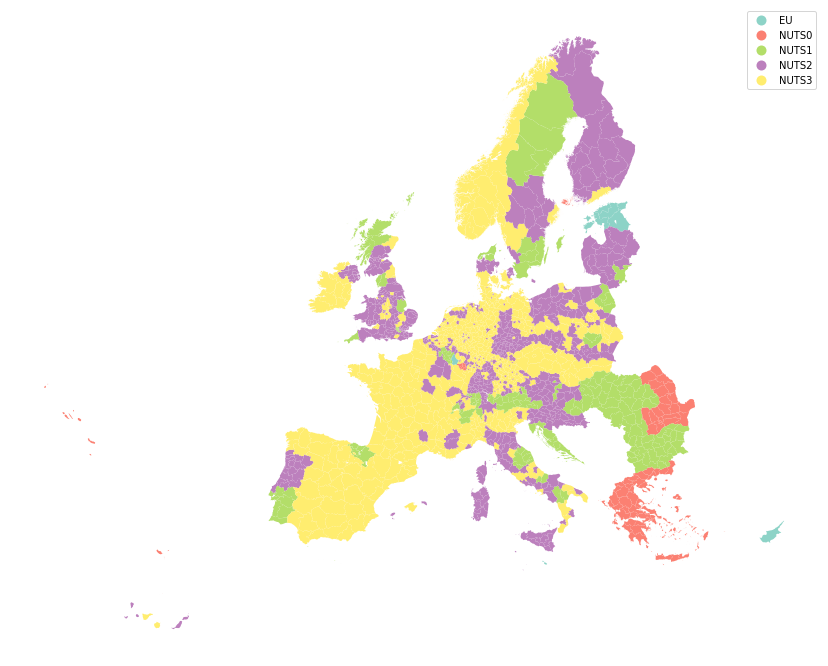

In [12]:
model_scope.plot(column='type', categorical=True, legend=True, figsize=(16, 12), missing_kwds={"color": "lightgrey"}, cmap='Set3').set_axis_off()

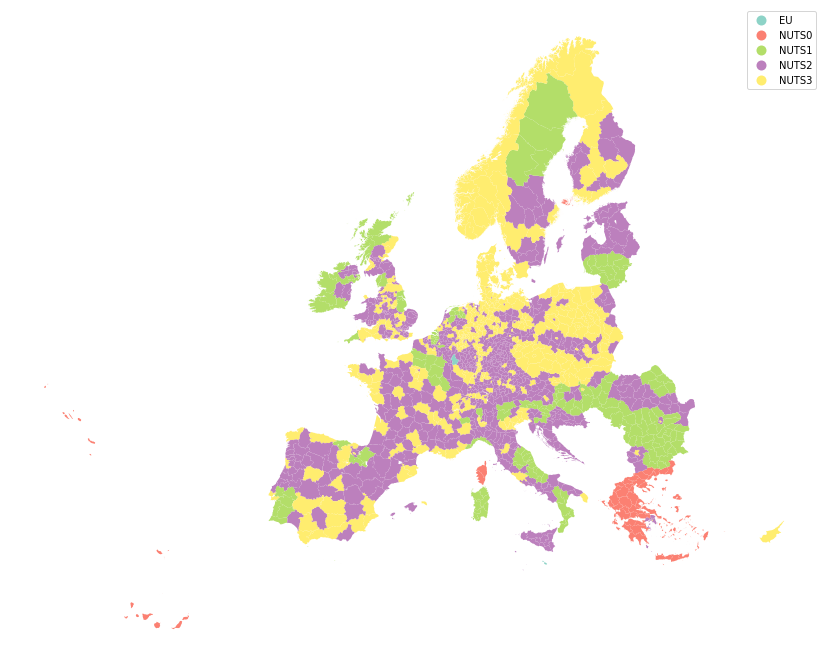

In [15]:
model_scope.plot(column='residential_type', categorical=True, legend=True, figsize=(16, 12), missing_kwds={"color": "lightgrey"}, cmap='Set3').set_axis_off()

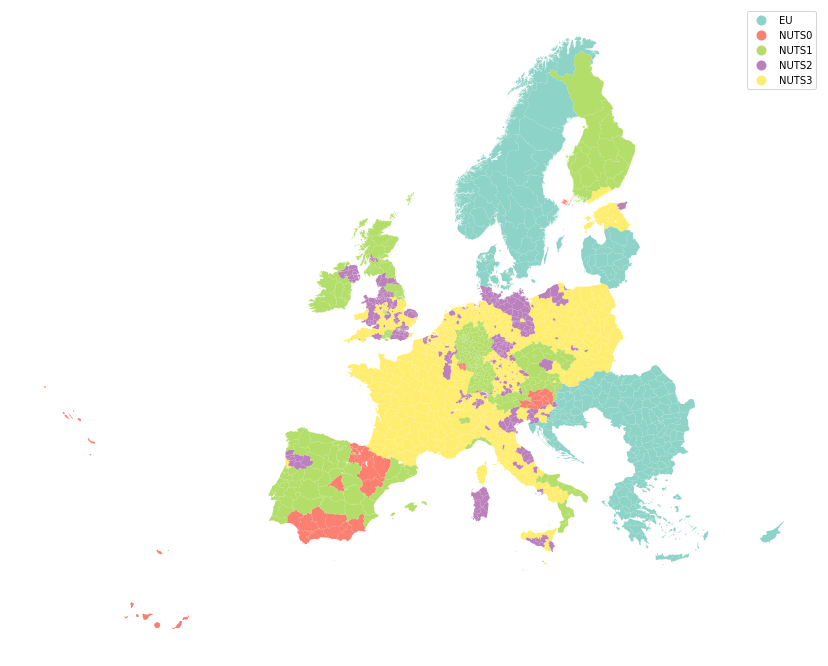

In [13]:
model_scope.plot(column='height', categorical=True, legend=True, figsize=(16, 12), missing_kwds={"color": "lightgrey"}, cmap='Set3').set_axis_off()

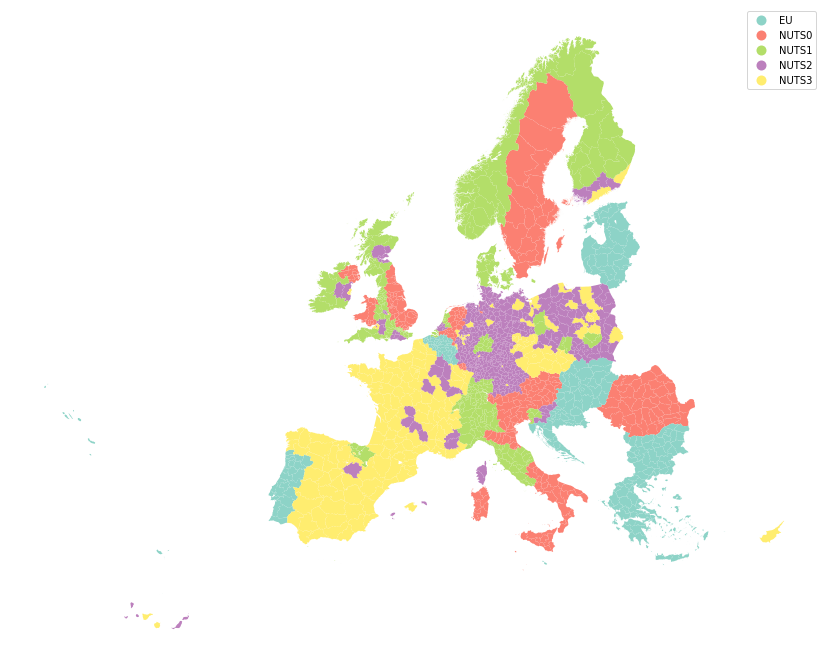

In [14]:
model_scope.plot(column='floors', categorical=True, legend=True, figsize=(16, 12), missing_kwds={"color": "lightgrey"}, cmap='Set3').set_axis_off()

### Prediction approach shares

In [50]:
attr_coverage_nuts[["model_height", "model_floors", "model_age", "model_type", "model_residential_type"]].apply(pd.value_counts, normalize=True).round(2)

,model_height,model_floors,model_age,model_type,model_residential_type
EU_model,0.17,0.16,0.48,0.01,0.00
NUTS1_model,0.24,0.19,0.02,0.13,0.13
NUTS2_model,0.23,0.32,0.03,0.44,0.53
NUTS3_model,0.33,0.14,0.12,0.37,0.30
country_model,0.03,0.19,0.35,0.06,0.04


In [ ]:
attr_coverage_nuts.set_index('country')[["model_height", "model_type", "model_age", "model_residential_type"]].eq(nuts3_m).groupby(level=0).mean().round(2)

,model_height,model_type,model_age,model_residential_type
country,,,,
AT,0.03,0.00,0.00,0.00
BE,0.66,0.00,0.00,0.00
BG,0.00,0.00,0.00,0.00
CH,0.38,0.00,0.00,0.00
CY,0.00,0.00,0.00,0.00
CZ,0.07,0.00,0.00,0.00
DE,0.30,0.48,0.00,0.00
DK,0.00,0.00,0.00,0.00
EE,0.80,0.00,0.00,0.00


['/p/projects/eubucco/data/5-feature-engineering/NO041.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO043.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO021.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO034.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO053.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO060.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO051.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO073.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO042.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO032.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO022.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO052.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO031.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO072.parquet',
 '/p/projects/eubucco/data/5-feature-engineering/NO033.parquet',
 '/p/projects/eubucco/dat

In [6]:
import glob
from pathlib import Path
gdfs = []
DATA_DIR = Path('/p/projects/eubucco/data/5-feature-engineering')

for path in glob.glob(str(DATA_DIR / 'NO*.parquet')):
    try:
        gdf = gpd.read_parquet(path)
        gdf = gdf[(gdf['source_dataset'] == 'osm') & (gdf['residential_type'].notna())]
        gdfs.append(gdf)
    except FileNotFoundError:
        print(f'NUTS region {nuts_region} not found. Skipping and continuing...')

gdf = gpd.GeoDataFrame(pd.concat(gdfs, ignore_index=True))

In [7]:
gdf

,id_source,LAU_ID,height,type_source,type,age,floors,source_file,geometry,residential_type,...,ghs_height_buffer_500,ghs_greenness_buffer_500,ghs_type_share_residential_buffer_500,ghs_type_share_non_residential_buffer_500,population_within_buffer_0.74km2,i_distance_to_built,i_distance_to_built_x_population,i_distance_to_built_x_population_x_footprint_area,i_distance_to_built_x_total_footprint_area,i_population_per_footprint_area
0,norway-latest_1191049,NO0901,3.0,cabin,residential,NaN,1.0,norway-latest,"POLYGON ((4266900.626 3958792.848, 4266909.479...",detached single-family house,...,3.000000,0.601746,0.030193,0.000000,0.091641,1.496628,0.137152,0.578623,24.899346,0.005508
1,norway-latest_1191054,NO0901,3.0,cabin,residential,NaN,1.0,norway-latest,"POLYGON ((4266890.215 3958792.184, 4266897.075...",detached single-family house,...,3.000000,0.600000,0.030879,0.000000,0.091641,1.224164,0.112183,0.471477,20.366376,0.005508
2,norway-latest_1191059,NO0901,3.0,cabin,residential,NaN,1.0,norway-latest,"POLYGON ((4266879.642 3958789.431, 4266888.229...",detached single-family house,...,3.000000,0.598302,0.030977,0.000000,0.091641,1.224164,0.112183,0.471308,20.366376,0.005508
3,norway-latest_1191064,NO0901,3.0,cabin,residential,NaN,1.0,norway-latest,"POLYGON ((4266869.973 3958787.801, 4266876.607...",detached single-family house,...,3.000000,0.599396,0.032154,0.000000,20.634401,1.397926,28.845359,121.249685,23.257235,1.240275
4,norway-latest_1191079,NO0901,6.0,house,residential,NaN,2.0,norway-latest,"POLYGON ((4269072.509 3955140.694, 4269073.631...",detached single-family house,...,NaN,NaN,0.000000,0.000000,0.000000,12.208025,0.000000,0.000000,29.520644,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1858046,norway-latest_326701,NO0219,NaN,house,residential,NaN,NaN,norway-latest,"POLYGON ((4354918.107 4090451.701, 4354921.508...",detached single-family house,...,10.144981,0.715094,0.307911,0.008529,107.488968,0.000000,0.000000,0.000000,0.000000,1.000593
1858047,norway-latest_334880,NO0219,NaN,house,residential,NaN,NaN,norway-latest,"POLYGON ((4356198.374 4087564.213, 4356212.696...",detached single-family house,...,6.280017,0.620667,0.187433,0.043623,29.560102,6.387310,188.809537,933.959603,361.914724,0.521696
1858048,norway-latest_328208,NO0219,NaN,house,residential,NaN,NaN,norway-latest,"POLYGON ((4355154.295 4091166.527, 4355159.576...",detached single-family house,...,9.798682,0.720184,0.277620,0.012352,63.664322,1.978372,125.951716,584.854372,184.768454,0.681673
1858049,norway-latest_717786,NO0211,NaN,apartments,residential,NaN,NaN,norway-latest,"POLYGON ((4360381.499 4044793.713, 4360384.062...",apartment block,...,3.315091,0.654095,0.174101,0.003235,8.207986,4.953544,40.658622,222.664633,301.353860,0.134920


In [161]:
LAU_FILE_PATH = '/p/projects/eubucco/data/0-raw-data/lau/lau_nuts.gpkg'
DATA_DIR = '/p/projects/eubucco/data/5-feature-engineering'
# gdf = gpd.read_parquet('/p/projects/eubucco/data/5-feature-engineering/NO051.parquet')#, filters=[('residential_type', '==', "apartment block")])
# gdf['source_dataset'].value_counts()

# def create_test_dataset():
gdfs = []
nuts_regions = gpd.read_file(LAU_FILE_PATH)['NUTS_ID'].drop_duplicates().sample(frac=0.2, random_state=42).tolist()

for nuts_region in nuts_regions:
    try:
        gdf = gpd.read_parquet(f'{DATA_DIR}/{nuts_region}.parquet')
        gdf = gdf[(gdf['source_dataset'] == 'osm') & (gdf['residential_type'].notna())].sample(frac=0.2, random_state=42)
        gdfs.append(gdf)
    except FileNotFoundError:
        print(f'NUTS region {nuts_region} not found. Skipping and continuing...')

gdf = gpd.GeoDataFrame(pd.concat(gdfs, ignore_index=True))
# df = eubucco.utils.load_df('/p/projects/eubucco/data/3-ml-inputs-v1/*.parquet', frac=0.1)
gdf.to_parquet('/p/projects/eubucco/data/5-feature-engineering/residential_type_0.1.parquet')

# create_test_dataset()

NUTS region FRG02 not found. Skipping and continuing...
NUTS region CZ042 not found. Skipping and continuing...
NUTS region BE213 not found. Skipping and continuing...
NUTS region FRE12 not found. Skipping and continuing...
NUTS region FRJ23 not found. Skipping and continuing...
NUTS region DK032 not found. Skipping and continuing...
NUTS region FRG05 not found. Skipping and continuing...
NUTS region BE222 not found. Skipping and continuing...
NUTS region BE231 not found. Skipping and continuing...
NUTS region BE233 not found. Skipping and continuing...
NUTS region FRG01 not found. Skipping and continuing...
NUTS region DE300 not found. Skipping and continuing...
NUTS region FRH01 not found. Skipping and continuing...
NUTS region FRH02 not found. Skipping and continuing...


In [162]:
gdf

,id_source,LAU_ID,height,type_source,type,age,floors,source_file,geometry,residential_type,height_source,dataset,area_share_intersected,block_id,msft_matching_confidence,msft_height_source_ids,msft_height_merged,msft_height_confidence,msft_height_unit_ioa,msft_height_unit_iou,msft_age_source_ids,msft_age_merged,msft_age_confidence,msft_age_unit_ioa,msft_age_unit_iou,msft_type_source_ids,msft_type_merged,msft_type_confidence,msft_type_unit_ioa,msft_type_unit_iou,msft_residential_type_source_ids,msft_residential_type_merged,msft_residential_type_confidence,msft_residential_type_unit_ioa,msft_residential_type_unit_iou,id,source_dataset,h3_index,bldg_multi_part,bldg_height,bldg_age,bldg_type,bldg_res_type,bldg_msft_height,bldg_footprint_area,bldg_perimeter,bldg_normalized_perimeter_index,bldg_area_perimeter_ratio,bldg_phi,bldg_longest_axis_length,bldg_elongation,bldg_convexity,bldg_rectangularity,bldg_orientation,bldg_corners,bldg_shared_wall_length,bldg_rel_courtyard_size,bldg_touches,bldg_distance_closest,validation,block_uuid,block_length,block_perimeter,block_footprint_area,block_avg_footprint_area,block_std_footprint_area,block_normalized_perimeter_index,block_area_perimeter_ratio,block_phi,block_longest_axis_length,block_elongation,block_convexity,block_rectangularity,block_orientation,block_corners,block_shared_wall_length,block_rel_courtyard_size,block_touches,block_distance_closest,neighbors_distance_public,neighbors_distance_industrial,neighbors_distance_commercial,neighbors_distance_agriculture,neighbors_distance_residential,neighbors_distance_residential_AB,neighbors_distance_residential_SFH,neighbors_distance_residential_TH,neighbors_distance_residential_DH,neighbors_distance_non_residential,neighbors_closest_building_height,neighbors_distance_low_rise,neighbors_distance_low_medium_rise,neighbors_distance_medium_rise,neighbors_distance_high_rise,neighbors_closest_building_age,neighbors_distance_prior_1900,neighbors_distance_1900_1970,neighbors_distance_1970_2000,neighbors_distance_after_2000,bldg_msft_height_closest,bldg_msft_distance_low_rise,bldg_msft_distance_low_medium_rise,bldg_msft_distance_medium_rise,bldg_msft_distance_high_rise,street_size,street_distance,street_alignment,poi_distance_commercial,poi_distance_industrial,poi_distance_education,poi_distance_non_residential,lu_distance_industrial,lu_distance_agriculture,lu_distance_dense_urban,lu_distance_coast,ghs_distance_residential,ghs_distance_non_residential,ghs_distance_high_rise,ghs_closest_height,ghs_closest_height_pooled_3,ghs_closest_height_pooled_5,ghs_closest_height_pooled_10,elevation,h3_8,ruggedness,cdd,hdd,population,nuts_mountain_type,nuts_coast_type,nuts_urban_type,country,h3_08,pc0,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,pc10,pc11,pc12,pc13,pc14,pc15,pc16,pc17,pc18,pc19,pc20,pc21,pc22,pc23,pc24,pc25,pc26,pc27,pc28,pc29,pc30,pc31,pc32,pc33,pc34,pc35,pc36,pc37,pc38,pc39,pc40,pc41,pc42,pc43,pc44,pc45,pc46,pc47,pc48,pc49,pc50,pc51,pc52,pc53,pc54,pc55,pc56,pc57,pc58,pc59,pc60,pc61,pc62,pc63,lng,lat,bldg_n_within_buffer_0.02km2,bldg_max_height_within_buffer_0.02km2,bldg_min_height_within_buffer_0.02km2,bldg_std_height_within_buffer_0.02km2,bldg_max_age_within_buffer_0.02km2,bldg_min_age_within_buffer_0.02km2,bldg_std_age_within_buffer_0.02km2,bldg_type_variety_within_buffer_0.02km2,bldg_res_type_variety_within_buffer_0.02km2,bldg_avg_msft_height_within_buffer_0.02km2,bldg_max_msft_height_within_buffer_0.02km2,bldg_min_msft_height_within_buffer_0.02km2,bldg_std_msft_height_within_buffer_0.02km2,bldg_total_footprint_area_within_buffer_0.02km2,bldg_avg_footprint_area_within_buffer_0.02km2,bldg_std_footprint_area_within_buffer_0.02km2,bldg_max_footprint_area_within_buffer_0.02km2,bldg_avg_perimeter_within_buffer_0.02km2,bldg_std_perimeter_within_buffer_0.02km2,bldg_max_perimeter_within_buffer_0.02km2,bldg_avg_elongation_within_buffer_0.02km2,bldg_std_elongation_within_buffer_0.02km2,bldg_max_elongation_within_buffer_0.02km2,bldg_avg_convexity_within_buffer_0

In [159]:
dirA = "/p/projects/eubucco/data/4-merged-dataset-ml-cleaned"
dirB = "/p/projects/eubucco/data/5-feature-engineering"

import glob
import os
from pathlib import Path

def parquet_files_only_in_dirA_with_sizes(dirA, dirB):
    # Get all .parquet files (non-recursive)
    filesA = {Path(f).stem for f in glob.glob(dirA + "/*.parquet", recursive=True)}
    filesB = {Path(f).stem for f in glob.glob(dirB + "/*.parquet", recursive=True)}
    print(f"Files in A: {len(filesA)}, Files in B: {len(filesB)}")
    
    # Files present in A but not in B
    missing_files = [file for file in filesA if file not in filesB]

    print("\n  -", "\n  - ".join(sorted(missing_files)))
    # # Collect sizes in GB
    # file_sizes = [(Path(f).stem, os.path.getsize(f) / (1024 ** 3)) for f in missing_files]
    
    # # Sort by size (largest first)
    # file_sizes.sort(key=lambda x: x[1], reverse=True)
    
    # return file_sizes


missing_with_sizes = parquet_files_only_in_dirA_with_sizes(dirA, dirB)

# print("Parquet files present in A but not in B:\n")
# for name, size_gb in missing_with_sizes:
#     print(f"{name:50s} {size_gb:8.3f} GB")

# total_gb = sum(size for _, size in missing_with_sizes)
# print(f"\nTotal size of missing files: {total_gb:.2f} GB")


Files in A: 1323, Files in B: 1319

  - DE502
  - ITC4C
  - PT200
  - SE232


In [188]:
gdf[gdf["LAU_ID"] == gdf[gdf["country"] == "NO" ]["LAU_ID"].value_counts().index[4]].dropna(subset=['type_source'])[['geometry', 'type', 'type_source', 'residential_type', 'source_dataset', 'id']].explore('residential_type')

In [172]:
gdf[gdf["LAU_ID"] == gdf["LAU_ID"].value_counts().index[10]].dropna(subset=['type'])[['geometry', 'type', 'type_source', 'residential_type', 'source_dataset', 'id']].explore('residential_type')


In [177]:
region = 'UKK43'
gdf_no = gpd.read_parquet(data_path / f'{region}.parquet')

In [178]:
gdf_no[gdf_no["LAU_ID"] == gdf_no["LAU_ID"].value_counts().index[2]].dropna(subset=['type'])[['geometry', 'type', 'type_source', 'residential_type', 'source_dataset', 'id']].explore('residential_type')
